<a href="https://colab.research.google.com/github/tanishakhabe/global-emerging-markets-risk-prediction/blob/main/Global_Emerging_Markets_Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notes:
- convert to correct datatypes first, then do missing values check

# Predicting Private-Sector Default Rates Across Emerging Markets Using Panel Data Regression

## Research Question:
Are historical default rates predictive across countries?



Do countries exhibit systematically different default-risk levels?



Does incorporating macroeconomic information improve out-of-sample prediction?



Does one pooled regression generalize better than separate country-level models?

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import libraries
import pandas as pd
import sklearn

In [ ]:
# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/pandas ML practice/IFC_GEM.csv")

In [ ]:
df.head()

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,METRIC,CONTRACT_SIZE,CURRENCY_TYPE,SECTOR,PROJECT_TYPE,...,DEFAULT_ACTION_LABEL,RATING_GRADE_LABEL,FREQ_LABEL,DATABASE_ID_LABEL,UNIT_TYPE_LABEL,DECIMALS_LABEL,UNIT_MEASURE_LABEL,OBS_STATUS_LABEL,OBS_CONF_LABEL,UNIT_MULT_LABEL
0,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,ADR,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
1,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CI_LB_90,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
2,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CI_UB_90,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
3,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CP,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Number (real number),Two,Counterparts,Normal value,Public,Units
4,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,DT,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Number (real number),Two,Defaults,Normal value,Public,Units


In [ ]:
df.shape

(24944, 49)

In [ ]:
df.describe()

,TIME_PERIOD,OBS_VALUE,DECIMALS,UNIT_MULT
count,24944.000000,1.945000e+04,24944.0,24944.000000
mean,2012.915651,4.306087e+03,2.0,0.129650
std,10.455919,7.688111e+04,0.0,0.872424
min,1984.000000,0.000000e+00,2.0,0.000000
25%,2004.000000,0.000000e+00,2.0,0.000000
50%,2014.000000,2.560000e+00,2.0,0.000000
75%,2024.000000,5.000000e+01,2.0,0.000000
max,2025.000000,1.707389e+06,2.0,6.000000


In [ ]:
df.isna().sum()

,0
STRUCTURE,0
STRUCTURE_ID,0
ACTION,0
REF_AREA,0
INDICATOR,0
METRIC,0
CONTRACT_SIZE,0
CURRENCY_TYPE,0
SECTOR,0
PROJECT_TYPE,0


In [ ]:
df.dropna()
df.shape

(24944, 49)

In [ ]:
df.drop_duplicates()

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,METRIC,CONTRACT_SIZE,CURRENCY_TYPE,SECTOR,PROJECT_TYPE,...,DEFAULT_ACTION_LABEL,RATING_GRADE_LABEL,FREQ_LABEL,DATABASE_ID_LABEL,UNIT_TYPE_LABEL,DECIMALS_LABEL,UNIT_MEASURE_LABEL,OBS_STATUS_LABEL,OBS_CONF_LABEL,UNIT_MULT_LABEL
0,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,ADR,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
1,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CI_LB_90,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
2,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CI_UB_90,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
3,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,CP,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Number (real number),Two,Counterparts,Normal value,Public,Units
4,dataflow,IFC.CR:DF_GEM(2.0.0),I,EAS,IFC_GEM_PBD,DT,_T,_T,_T,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Number (real number),Two,Defaults,Normal value,Public,Units
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24939,dataflow,IFC.CR:DF_GEM(2.0.0),I,MKD,IFC_GEM_PRD_H,ADR,_T,_T,NF,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
24940,dataflow,IFC.CR:DF_GEM(2.0.0),I,MKD,IFC_GEM_PRD_H,ADR,_T,_T,NF,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
24941,dataflow,IFC.CR:DF_GEM(2.0.0),I,MKD,IFC_GEM_PRD_H,ADR,_T,_T,NF,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units
24942,dataflow,IFC.CR:DF_GEM(2.0.0),I,MKD,IFC_GEM_PRD_H,ADR,_T,_T,NF,_T,...,Overall,Overall,Annual,Global Emerging Markets Risk Database,Ratio,Two,Percentage,Normal value,Public,Units


In [ ]:
# Get rid of columns not needed for analysis.
df = df.drop(columns = ["STRUCTURE", "STRUCTURE_ID", "ACTION"])

df = df.loc[:,
    ~df.columns.str.endswith("_LABEL") |
    (df.columns == "REF_AREA_LABEL")
]

df.head()

,REF_AREA,INDICATOR,METRIC,CONTRACT_SIZE,CURRENCY_TYPE,SECTOR,PROJECT_TYPE,SENIORITY,DEFAULT_TYPE,RR_BAND,...,TIME_PERIOD,OBS_VALUE,DATABASE_ID,UNIT_TYPE,DECIMALS,UNIT_MEASURE,OBS_STATUS,OBS_CONF,UNIT_MULT,REF_AREA_LABEL
0,EAS,IFC_GEM_PBD,ADR,_T,_T,_T,_T,_T,_T,_T,...,2025,2.99,IFC_GEM,RATIO,2,PT,A,PU,0,East Asia & Pacific
1,EAS,IFC_GEM_PBD,CI_LB_90,_T,_T,_T,_T,_T,_T,_T,...,2025,1.76,IFC_GEM,RATIO,2,PT,A,PU,0,East Asia & Pacific
2,EAS,IFC_GEM_PBD,CI_UB_90,_T,_T,_T,_T,_T,_T,_T,...,2025,4.22,IFC_GEM,RATIO,2,PT,A,PU,0,East Asia & Pacific
3,EAS,IFC_GEM_PBD,CP,_T,_T,_T,_T,_T,_T,_T,...,2025,42.00,IFC_GEM,NUMBER,2,CP,A,PU,0,East Asia & Pacific
4,EAS,IFC_GEM_PBD,DT,_T,_T,_T,_T,_T,_T,_T,...,2025,13.00,IFC_GEM,NUMBER,2,DF,A,PU,0,East Asia & Pacific


In [ ]:
# 1. Select historical private-sector average default rates
df = df[
    (df["INDICATOR"] == "IFC_GEM_PRD_H") &
    (df["METRIC"] == "ADR") &
    (df["SECTOR"] == "_T")
].copy()

In [ ]:
df.shape

(3296, 25)

In [ ]:
# EDA

In [ ]:
df[["REF_AREA", "REF_AREA_LABEL"]].value_counts()

,,count
REF_AREA,REF_AREA_LABEL,
002,Africa,32
003,North America,32
005,South America,32
009,Oceania,32
142,Asia,32
...,...,...
WLD,World,32
XKX,Kosovo,32
ZAF,South Africa,32


In [ ]:
# Keep individual countries only, exclude geographic aggregates.

# Remove rows with numeric REF_AREA codes because those represent the geographic aggregates.

import pycountry

# ISO country codes
country_codes = {country.alpha_3 for country in pycountry.countries}

# Include Kosovo
country_codes.add("XKX")

# Filter country-level observations
df = df[df["REF_AREA"].isin(country_codes)].copy()

print("Countries:", df["REF_AREA"].nunique())
print("Rows:", len(df))

Countries: 90
Rows: 2880


In [ ]:
# Rename all of the columns for the analysis
df = df[["REF_AREA", "REF_AREA_LABEL", "TIME_PERIOD", "OBS_VALUE"]].rename(
    columns={"REF_AREA": "country",
    "REF_AREA_LABEL": "country_name",
    "TIME_PERIOD": "year",
    "OBS_VALUE": "default_rate"
})

df.head()


,country,country_name,year,default_rate
9585,ALB,Albania,1994,0.00
9586,ALB,Albania,1995,0.00
9587,ALB,Albania,1996,0.00
9588,ALB,Albania,1997,0.00
9589,ALB,Albania,1998,33.33


In [ ]:
# 4. Convert values to numeric


df["default_rate"] = pd.to_numeric(
    df["default_rate"], errors="coerce"
)
df.dtypes


,0
country,object
country_name,object
year,int64
default_rate,float64


In [ ]:
df = df.sort_values(["country", "year"])
print("Rows:", len(df))
print("Missing rates:", df["default_rate"].isna().sum())

Rows: 2880
Missing rates: 252


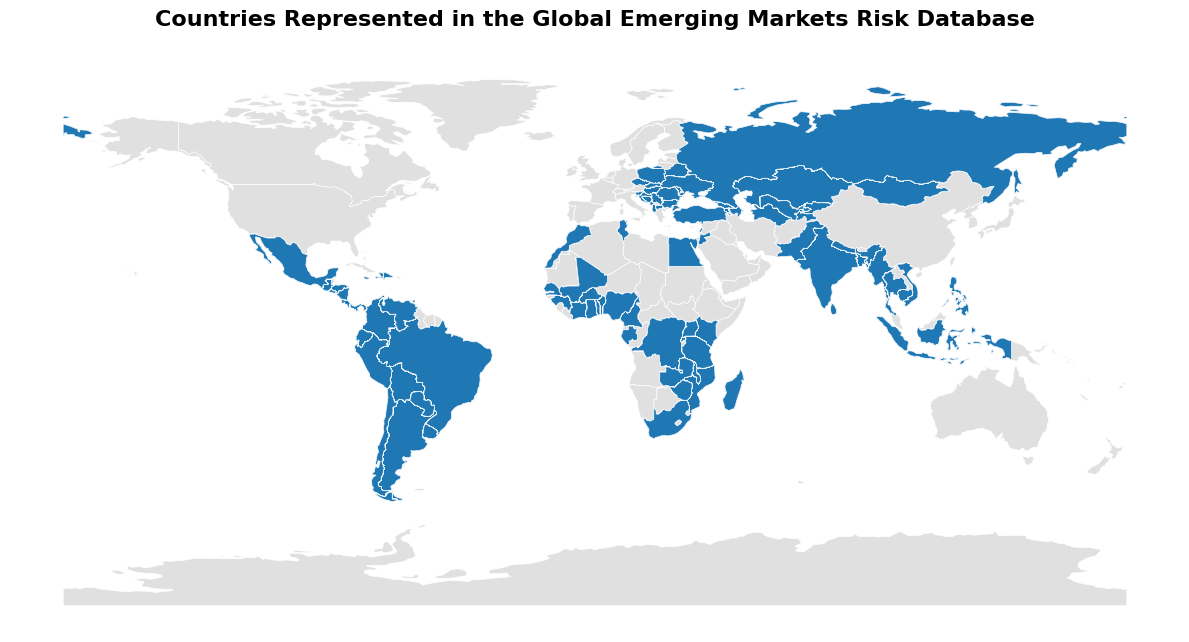

In [ ]:
# Map of all countries represented in the data
import geopandas as gpd
import matplotlib.pyplot as plt

df['represented'] = 1

# Load the low-resolution world map directly from the public GeoJSON source
url = "https://raw.githubusercontent.com/datasets/geo-boundaries-world-110m/master/countries.geojson"
world = gpd.read_file(url)

# Natural Earth uses 3-letter ISO codes in different column names depending on the source (often 'ISO_A3' or 'iso3')
# Let's inspect or rename the code column to match our 'country' column (which has 3-letter codes)
iso3_col = [col for col in world.columns if 'iso' in col.lower() or 'code' in col.lower() or 'a3' in col.lower()]

# Typically, this GeoJSON uses "iso3"
join_col = iso3_col[0] if iso3_col else "iso3"

merged = world.merge(df, left_on=join_col, right_on='country', how='left')
merged['represented'] = merged['represented'].fillna(0)

fig, ax = plt.subplots(figsize=(12, 7))

# Plot unrepresented countries in light grey
merged[merged['represented'] == 0].plot(
    ax=ax, color='#E0E0E0', edgecolor='#FFFFFF', linewidth=0.5
)

# Plot represented countries in a distinct, solid color
merged[merged['represented'] == 1].plot(
    ax=ax, color='#1F77B4', edgecolor='#FFFFFF', linewidth=0.5,
    label='Represented Countries'
)

# Customize the final layout
ax.set_title('Countries Represented in the Global Emerging Markets Risk Database', fontsize=16, fontweight='bold', pad=20)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
# Plot rates, obs value by countries